In [25]:
# Cell 1 — Config (13_44)
from pathlib import Path
import pandas as pd
import cv2

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

VIDEO_DIR = ROOT / "data" / "videos_13_44"
LOG_DIR   = ROOT / "data" / "log"


LOG_FILE = [p for p in LOG_DIR.glob("*.xlsx") if not p.name.startswith("~$")][0]
SHEET    = pd.ExcelFile(LOG_FILE).sheet_names[0]

CAMERAS = {
    "13_44": {
        "front":      VIDEO_DIR / "13_44_front_cropped.mp4",
        "back_left":  VIDEO_DIR / "13_44_back_left_cropped.mp4",
        "back_right": VIDEO_DIR / "13_44_back_right_cropped.mp4",
           
    },
}

GT_XLSX = {
    "13_44": (ROOT / "data" / "log" / "13_44_ground_truth_ai_app.xlsx", "13_44_ground_truth"),
}
VIDEO_START = {
    "13_44": pd.Timestamp("2025-03-26 13:44:00"),
}

OUT_DIR = ROOT / "data" / "ocr_frames_13_44"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ROOT / "results" / "cvat_training" / "yolo11n_cvat_all" / "weights" / "best.pt"
CROP_BAND = (0.20, 0.75)  


CAM_PRIORITY = {"back_right": 0, "front": 1, "back_left": 2}
CAM_OFFSET = {"front": 0, "back_left": 1, "back_right": 1}

print("model:", MODEL_PATH.exists(), MODEL_PATH.name)
for vk, cams in CAMERAS.items():
    for cam, p in cams.items():
        print(f"{vk}/{cam:10s}", p.exists(), p.name)
print("gt files:")
for vk, (p, s) in GT_XLSX.items():
    print(" ", vk, p.exists(), p.name, "->", s)
print("output:", OUT_DIR.relative_to(ROOT))

model: True best.pt
13_44/front      True 13_44_front_cropped.mp4
13_44/back_left  True 13_44_back_left_cropped.mp4
13_44/back_right True 13_44_back_right_cropped.mp4
gt files:
  13_44 True 13_44_ground_truth_ai_app.xlsx -> 13_44_ground_truth
output: data/ocr_frames_13_44


In [26]:
#cell 2
gt_rows = []
for vk, (xlsx_path, sheet) in GT_XLSX.items():
    df = pd.read_excel(xlsx_path, sheet_name=sheet)

    # numeric GT fields (keep bottles with "?" -> they become empty/NaN)
    df["gt_tare"] = pd.to_numeric(df["tarra"], errors="coerce")
    df["gt_year"] = pd.to_numeric(df["year"], errors="coerce")

    # timestamps → seconds since video start
    df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
    df["t_sec"] = (df["Time"] - VIDEO_START[vk]).dt.total_seconds()

    # drop rows with nonsense timestamps
    df = df[(df["t_sec"] >= -1) & (df["t_sec"] <= 10000)].copy()

    # drop rows past the end of the video (length read from the front video)
    cap = cv2.VideoCapture(str(CAMERAS[vk]["front"]))
    video_len_s = cap.get(cv2.CAP_PROP_FRAME_COUNT) / cap.get(cv2.CAP_PROP_FPS)
    cap.release()
    print(f"{vk}: video length {video_len_s:.0f} s")
    df = df[df["t_sec"] <= video_len_s].copy()

    # Sequence (fall back to row index if the column is missing)
    if "Sequence" not in df.columns:
      df["Sequence"] = range(len(df))
    
    df["Sequence"] = pd.to_numeric(df["Sequence"], errors="coerce")
    df = df.dropna(subset=["Sequence"]).copy()
    df["Sequence"] = df["Sequence"].astype(int)

    # colour
    df["color"] = (df["color"].astype(str).str.strip().str.lower()
                   if "color" in df.columns else "?")

    for _, r in df.iterrows():
        gt_rows.append({
            "video": vk,
            "Sequence": int(r["Sequence"]),
            "t_sec": float(r["t_sec"]),
            "gt_tare": r["gt_tare"],   # can be empty
            "gt_year": r["gt_year"],   # can be empty
            "color": r["color"],
        })

gt_targets = (pd.DataFrame(gt_rows)
              .sort_values(["video", "t_sec"])
              .reset_index(drop=True))

print("target bottles:", len(gt_targets))
print(gt_targets.groupby("video").size())
print("colours:", gt_targets.groupby("color").size().to_dict())
print("t_sec range per video:")
print(gt_targets.groupby("video")["t_sec"].agg(["min", "max"]))
gt_targets.head()

13_44: video length 715 s
target bottles: 149
video
13_44    149
dtype: int64
colours: {'black': 130, 'cyan': 19}
t_sec range per video:
        min    max
video             
13_44  25.0  684.0


,video,Sequence,t_sec,gt_tare,gt_year,color
0,13_44,541904,25.0,10.66,2039.0,black
1,13_44,541905,32.0,15.40,2035.0,black
2,13_44,541906,39.0,NaN,NaN,cyan
3,13_44,541907,42.0,16.40,2036.0,black
4,13_44,541908,45.0,10.50,2035.0,black


In [27]:
for cam, p in CAMERAS["13_44"].items():
    cap = cv2.VideoCapture(str(p))
    frames, fps = cap.get(cv2.CAP_PROP_FRAME_COUNT), cap.get(cv2.CAP_PROP_FPS)
    print(f"{cam:10s} opened={cap.isOpened()}  length={frames/fps if fps else 0:.0f} s  size={p.stat().st_size/1e6:.0f} MB")
    cap.release()

front      opened=True  length=715 s  size=3330 MB
back_left  opened=True  length=715 s  size=3076 MB
back_right opened=True  length=715 s  size=2845 MB


In [32]:
# Cell 3 — For every GT bottle, grab 1 shoulder crop per camera (3 total)


from ultralytics import YOLO

model = YOLO(str(MODEL_PATH))
print("model classes:", model.names)

def shoulder_crop(frame):
    """Detect bottle in frame, return (crop, box) or (None, None)."""
    res = model.predict(frame, conf=0.25, verbose=False)
    if not res or res[0].boxes is None or len(res[0].boxes) == 0:
        return None, None
    boxes = res[0].boxes.xyxy.cpu().numpy()
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    i = int(areas.argmax())
    x1, y1, x2, y2 = boxes[i].astype(int)
    h = y2 - y1
    crop = frame[y1 + int(h * CROP_BAND[0]): y1 + int(h * CROP_BAND[1]), x1:x2]
    if crop.size == 0:
        return None, None
    return crop, boxes[i]

# Clear old crops from previous runs
for p in list(OUT_DIR.glob("crop_*.jpg")) + list(OUT_DIR.glob("full_*.jpg")):
    p.unlink()

# Open one VideoCapture per (session, camera), all kept open at the same time
caps = {vk: {cam: cv2.VideoCapture(str(path)) for cam, path in cams.items()}
        for vk, cams in CAMERAS.items()}

manifest = []
for _, row in gt_targets.iterrows():
    vk, seq, t_sec = row["video"], int(row["Sequence"]), float(row["t_sec"])
    for cam, cap in caps[vk].items():
        cap.set(cv2.CAP_PROP_POS_MSEC, (t_sec + CAM_OFFSET[cam]) * 1000.0)
        ok, frame = cap.read()
        if not ok:
            continue
        crop, box = shoulder_crop(frame)
        if crop is None:
            continue

        # shoulder crop (for OCR)
        out_path = OUT_DIR / f"crop_{vk}_{seq:06d}_{cam}.jpg"
        cv2.imwrite(str(out_path), crop)

        # full bottle crop (for the OK/NOK classifier)
        x1, y1, x2, y2 = box.astype(int)
        full_path = OUT_DIR / f"full_{vk}_{seq:06d}_{cam}.jpg"
        cv2.imwrite(str(full_path), frame[y1:y2, x1:x2])

        manifest.append({
            "video": vk, "Sequence": seq, "t_sec": t_sec,
            "camera": cam, "priority": CAM_PRIORITY[cam],
            "crop_path": str(out_path.relative_to(ROOT)),
            "full_crop_path": str(full_path.relative_to(ROOT)),
            "gt_tare": row["gt_tare"], "gt_year": row["gt_year"],
            "color": row["color"],
        })

for vk in caps:
    for cap in caps[vk].values():
        cap.release()

manifest_df = pd.DataFrame(manifest)
manifest_path = OUT_DIR / "manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

print(f"\ncrops saved: {len(manifest_df)}")
print(f"per video:   {manifest_df.groupby('video').size().to_dict()}")
print(f"per camera:  {manifest_df.groupby('camera').size().to_dict()}")
bottles = manifest_df.groupby(["video", "Sequence"]).size()
print(f"bottles with 1 crop: {(bottles == 1).sum()}")
print(f"bottles with 2 crops: {(bottles == 2).sum()}")
print(f"bottles with 3 crops: {(bottles == 3).sum()}")
print("manifest:", manifest_path.relative_to(ROOT))

model classes: {0: 'gas-bottles'}

crops saved: 394
per video:   {'13_44': 394}
per camera:  {'back_left': 136, 'back_right': 144, 'front': 114}
bottles with 1 crop: 12
bottles with 2 crops: 23
bottles with 3 crops: 112
manifest: data/ocr_frames_13_44/manifest.csv


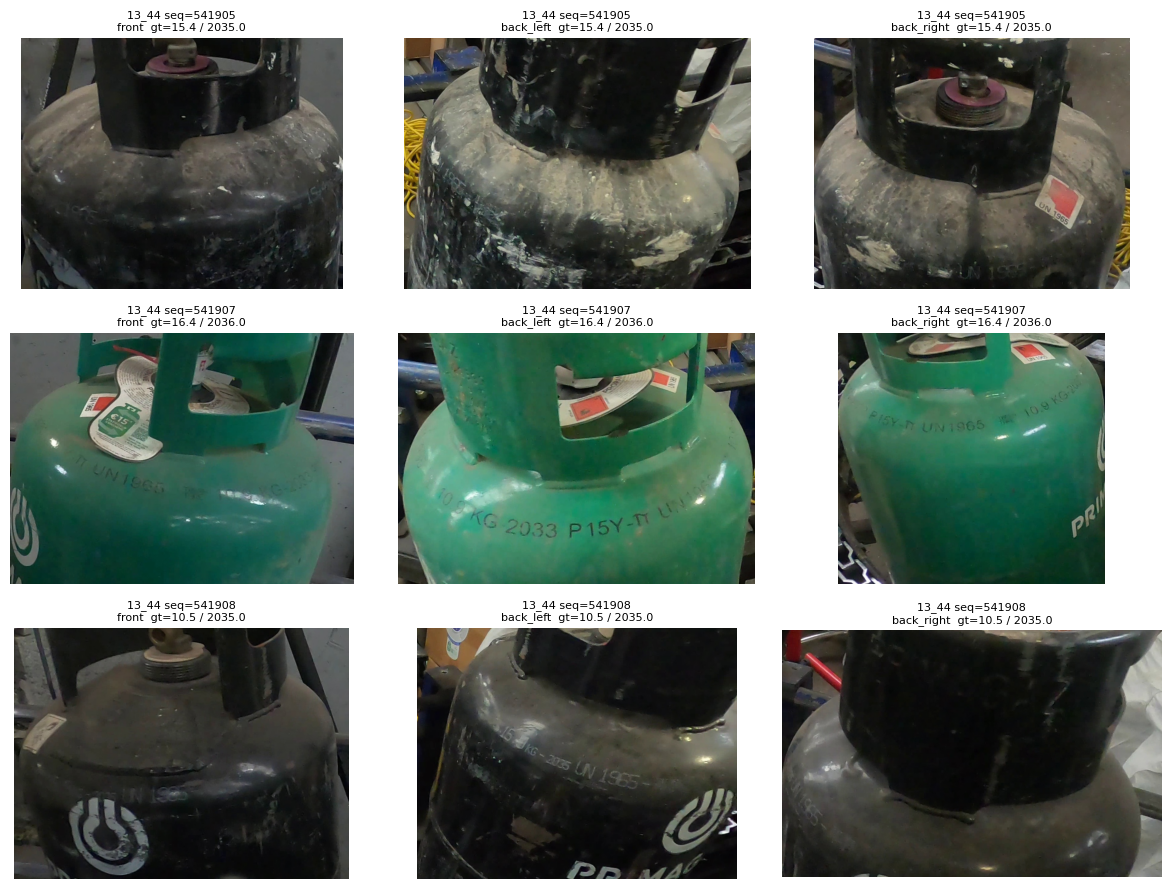

In [33]:
# Cell 4 — preview: 3 bottles × 3 cameras grid
import matplotlib.pyplot as plt

full = manifest_df.groupby(["video", "Sequence"]).size()
trio = full[full == 3].index.tolist()[:3]

fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for row_i, (vk, seq) in enumerate(trio):
    subset = manifest_df[(manifest_df.video == vk) & (manifest_df.Sequence == seq)]
    for col_i, cam in enumerate(["front", "back_left", "back_right"]):
        ax = axes[row_i, col_i]
        r = subset[subset.camera == cam]
        if len(r) == 0:
            ax.axis("off"); continue
        img = cv2.imread(str(ROOT / r.iloc[0].crop_path))
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{vk} seq={seq}\n{cam}  gt={r.iloc[0].gt_tare} / {r.iloc[0].gt_year}",
                     fontsize=8)
        ax.axis("off")
plt.tight_layout(); plt.show()

In [34]:
# Cell 5 — summary
print("=== Data preparation summary ===")
print(f"GT bottles (all, incl. '?')        : {len(gt_targets)}")
print(f"crops actually saved              : {len(manifest_df)}")
print(f"per camera                        : {manifest_df.groupby('camera').size().to_dict()}")
print(f"per colour                        : {manifest_df.groupby('color').size().to_dict()}")
print(f"bottles with 3 camera crops       : {(manifest_df.groupby(['video','Sequence']).size() == 3).sum()}")
print(f"crop band                          : {CROP_BAND}")
print(f"camera priority                    : {CAM_PRIORITY}")
print(f"output dir                         : {OUT_DIR.relative_to(ROOT)}")

=== Data preparation summary ===
GT bottles (all, incl. '?')        : 149
crops actually saved              : 394
per camera                        : {'back_left': 136, 'back_right': 144, 'front': 114}
per colour                        : {'black': 342, 'cyan': 52}
bottles with 3 camera crops       : 112
crop band                          : (0.2, 0.75)
camera priority                    : {'back_right': 0, 'front': 1, 'back_left': 2}
output dir                         : data/ocr_frames_13_44


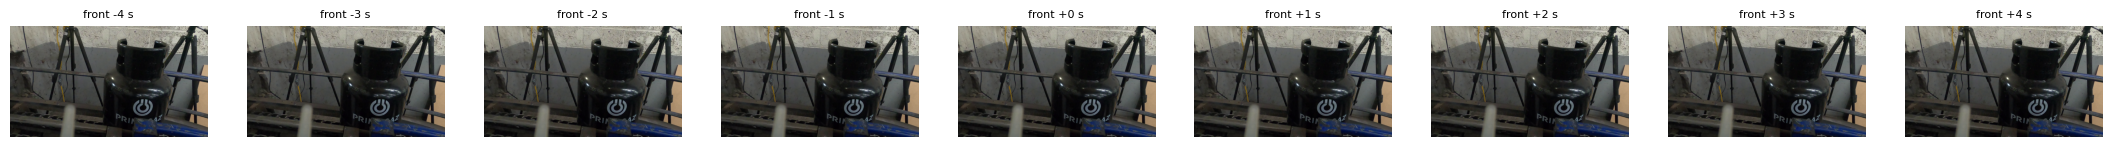

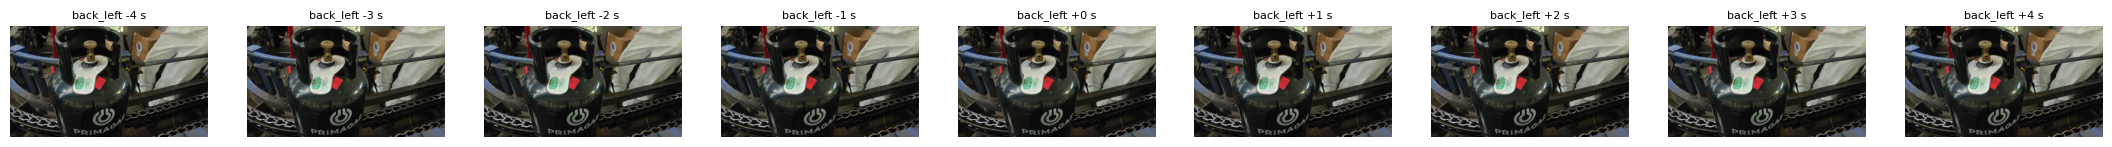

In [ ]:
import matplotlib.pyplot as plt

def show_offsets(seq, cam, offsets=range(-8, 9, 2)):
    r = gt_targets[gt_targets.Sequence == seq].iloc[0]
    cap = cv2.VideoCapture(str(CAMERAS["13_44"][cam]))
    fig, axes = plt.subplots(1, len(offsets), figsize=(3 * len(offsets), 3))
    for ax, off in zip(axes, offsets):
        cap.set(cv2.CAP_PROP_POS_MSEC, (r.t_sec + off) * 1000)
        ok, frame = cap.read()
        if ok:
            ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{cam} {off:+d} s", fontsize=8)
        ax.axis("off")
    cap.release()
    plt.show()

show_offsets(541907, "front",     range(-4, 5, 1))
show_offsets(541907, "back_left", range(-4, 5, 1))